In [0]:
import pandas as pd
import numpy as np

In [0]:
patient_readmission=spark.read.table( "machinelearning.default.expanded_patient_readmission_data_1").toPandas()

patient_readmission.head()

,Patient ID,Age,Gender,Admission Type,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions,Readmission
0,1,62,Female,Elective,4,5,110,130,1,No
1,2,65,Male,Emergency,19,2,157,81,4,No
2,3,82,Female,Emergency,18,4,74,84,0,No
3,4,85,Male,Emergency,2,4,106,85,4,No
4,5,85,Female,Elective,19,3,80,119,3,No


In [0]:
 #  Check the number of rows and columns
print("Dataset shape:", patient_readmission.shape)

Dataset shape: (3000, 10)


In [0]:
#. Check the data types of each column
patient_readmission.dtypes

Patient ID              int64
Age                     int64
Gender                 object
Admission Type         object
Length of Stay          int64
Number of Diagnoses     int64
Blood Pressure          int64
Blood Sugar Levels      int64
Previous Admissions     int64
Readmission            object
dtype: object

In [0]:
# Summary statistics for numerical columns
print("\nNumerical summary:")
display(patient_readmission.describe())


Numerical summary:


Patient ID,Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions
3000.0,3000.0,3000.0,3000.0,3000.0,3000.0,3000.0
1500.5,53.453,15.226333333333333,4.956666666666667,119.058,133.536,1.9583333333333333
866.1697293256098,20.89299635680791,8.264857884289647,2.5750726634335734,34.08926510401445,37.62631105704164,1.4016366923569539
1.0,18.0,1.0,1.0,60.0,51.0,0.0
750.75,35.0,8.0,3.0,89.75,101.0,1.0
1500.5,53.0,15.0,5.0,119.0,133.0,2.0
2250.25,72.0,22.0,7.0,147.25,167.0,3.0
3000.0,89.0,29.0,9.0,179.0,199.0,4.0


The average patient age is approximately 53 years.

The average hospital stay is approximately 15 days.

Patients have an average of approximately five diagnoses.

Previous admissions average approximately two per patient.

The recorded minimum and maximum values do not immediately suggest unrealistic values based on the dataset's stated ranges.

In [0]:
 # Define age ranges
age_bins = [17, 29, 39, 49, 59, 69, 79, 89]

# Give each age group a descriptive name
age_labels = [
    'Young Adults (18-29)',
    'Adults (30-39)',
    'Middle-aged Adults (40-49)',
    'Middle-aged Adults (50-59)',
    'Older Adults (60-69)',
    'Seniors (70-79)',
    'Elderly Adults (80-89)'
]

# Create the new age category
patient_readmission['Age_Bracket'] = pd.cut(
    patient_readmission['Age'],
    bins=age_bins,
    labels=age_labels
)

# Display age and category
patient_readmission[['Age', 'Age_Bracket']].head(10)

,Age,Age_Bracket
0,62,Older Adults (60-69)
1,65,Older Adults (60-69)
2,82,Elderly Adults (80-89)
3,85,Elderly Adults (80-89)
4,85,Elderly Adults (80-89)
5,27,Young Adults (18-29)
6,39,Adults (30-39)
7,54,Middle-aged Adults (50-59)
8,88,Elderly Adults (80-89)
9,30,Adults (30-39)


In [0]:
# Group patients by age bracket
age_readmission = patient_readmission.groupby(
    'Age_Bracket', observed=False
).agg(
    Total_Patients=('Readmission', 'count'),
    Readmitted=('Readmission', lambda x: (x == 'Yes').sum())
)

# Calculate readmission percentage
age_readmission['Readmission_Rate'] = (
    age_readmission['Readmitted'] /
    age_readmission['Total_Patients']
) * 100

# Display results
print(age_readmission.round(2))

                            Total_Patients  Readmitted  Readmission_Rate
Age_Bracket                                                             
Young Adults (18-29)                   493         131             26.57
Adults (30-39)                         429         118             27.51
Middle-aged Adults (40-49)             419         114             27.21
Middle-aged Adults (50-59)             412         130             31.55
Older Adults (60-69)                   397         111             27.96
Seniors (70-79)                        439         144             32.80
Elderly Adults (80-89)                 411         118             28.71


In [0]:
 
# Numerical summary
display(patient_readmission.describe())

# Categorical summary
display(patient_readmission.describe(include="object"))


Patient ID,Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions
3000.0,3000.0,3000.0,3000.0,3000.0,3000.0,3000.0
1500.5,53.453,15.226333333333333,4.956666666666667,119.058,133.536,1.9583333333333333
866.1697293256098,20.89299635680791,8.264857884289647,2.5750726634335734,34.08926510401445,37.62631105704164,1.4016366923569539
1.0,18.0,1.0,1.0,60.0,51.0,0.0
750.75,35.0,8.0,3.0,89.75,101.0,1.0
1500.5,53.0,15.0,5.0,119.0,133.0,2.0
2250.25,72.0,22.0,7.0,147.25,167.0,3.0
3000.0,89.0,29.0,9.0,179.0,199.0,4.0


Gender,Admission Type,Readmission
3000,3000,3000
2,2,2
Male,Elective,No
1555,1563,2134


Audit quality. Count missing values per column, duplicate rows and duplicate patient IDs. List the unique values
of each categorical column and check for inconsistent spelling, case or spacing. Check that numeric values fall
within plausible ranges (an age of 0 or a stay of 400 days would need explaini

In [0]:
 # 1. Check missing values per column
print("Missing values:")
print(patient_readmission.isnull().sum())

Missing values:
Patient ID             0
Age                    0
Gender                 0
Admission Type         0
Length of Stay         0
Number of Diagnoses    0
Blood Pressure         0
Blood Sugar Levels     0
Previous Admissions    0
Readmission            0
Age_Bracket            0
dtype: int64


In [0]:
 # 2. Check total missing values
print("\nTotal missing values:")
print(patient_readmission.isnull().sum().sum())


Total missing values:
0


In [0]:
 # 3. Check duplicate rows
print("\nDuplicate rows:")
print(patient_readmission.duplicated().sum())


Duplicate rows:
0


In [0]:
# 4. Check duplicate patient IDs
print("\nDuplicate Patient IDs:")
print(patient_readmission["Patient ID"].duplicated().sum())


Duplicate Patient IDs:
0


In [0]:
 # 5. Check unique categorical values
print("\nUnique categorical values:")

categorical_columns = [
    "Gender",
    "Admission Type",
    "Readmission"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(patient_readmission[column].unique())


Unique categorical values:

Gender:
['Female' 'Male']

Admission Type:
['Elective' 'Emergency']

Readmission:
['No' 'Yes']


Numerical validation was performed to identify values outside the expected ranges. Age ranged from 18 to 89 years, length of stay from 1 to 29 days, number of diagnoses from 1 to 9, blood pressure from 60 to 179, blood sugar levels from 51 to 199, and previous admissions from 0 to 4. No invalid values were detected in any of the numerical variables. Therefore, no numerical corrections or record removals were required.

In [0]:
 
# Define expected minimum and maximum values
expected_ranges = {
    "Age": (18, 89),
    "Length of Stay": (1, 29),
    "Number of Diagnoses": (1, 9),
    "Blood Pressure": (60, 179),
    "Blood Sugar Levels": (51, 199),
    "Previous Admissions": (0, 4)
}

# Check whether values fall within the expected ranges
for column, (minimum, maximum) in expected_ranges.items():

    invalid = patient_readmission[
        (patient_readmission[column] < minimum) |
        (patient_readmission[column] > maximum)
    ]

    print(f"\n{column}")
    print("Minimum:", patient_readmission[column].min())
    print("Maximum:", patient_readmission[column].max())
    print("Invalid values:", len(invalid))



Age
Minimum: 18
Maximum: 89
Invalid values: 0

Length of Stay
Minimum: 1
Maximum: 29
Invalid values: 0

Number of Diagnoses
Minimum: 1
Maximum: 9
Invalid values: 0

Blood Pressure
Minimum: 60
Maximum: 179
Invalid values: 0

Blood Sugar Levels
Minimum: 51
Maximum: 199
Invalid values: 0

Previous Admissions
Minimum: 0
Maximum: 4
Invalid values: 0


**Handle missing and invalid values. Decide, column by column, whether to impute (median, mode, KNN), flag or
remove, and justify each choice. If a column has no missing values, say so with evidence and state how you
would handle them if they appeared**

In [0]:
 
# Check missing values
print("Missing values before cleaning:")
print(patient_readmission.isnull().sum())

# Count total missing values
print("\nTotal missing values:")
print(patient_readmission.isnull().sum().sum())

# No imputation required because there are no missing values

print("\nMissing value treatment:")
print("No imputation required. All columns are complete.")


Missing values before cleaning:
Patient ID             0
Age                    0
Gender                 0
Admission Type         0
Length of Stay         0
Number of Diagnoses    0
Blood Pressure         0
Blood Sugar Levels     0
Previous Admissions    0
Readmission            0
Age_Bracket            0
dtype: int64

Total missing values:
0

Missing value treatment:
No imputation required. All columns are complete.


In [0]:
 
# Check duplicate rows
print("Duplicate rows:", patient_readmission.duplicated().sum())

# Check duplicate patient IDs
print("Duplicate Patient IDs:",
      patient_readmission["Patient ID"].duplicated().sum())

# No duplicate removal required
print("\nNo duplicate records need to be removed.")


Duplicate rows: 0
Duplicate Patient IDs: 0

No duplicate records need to be removed.


**Handle outliers. Identify them with box plots or the IQR rule, decide whether they are errors or real extremes, and
treat them accordingly. Removing them without a reason is not acceptab**

In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


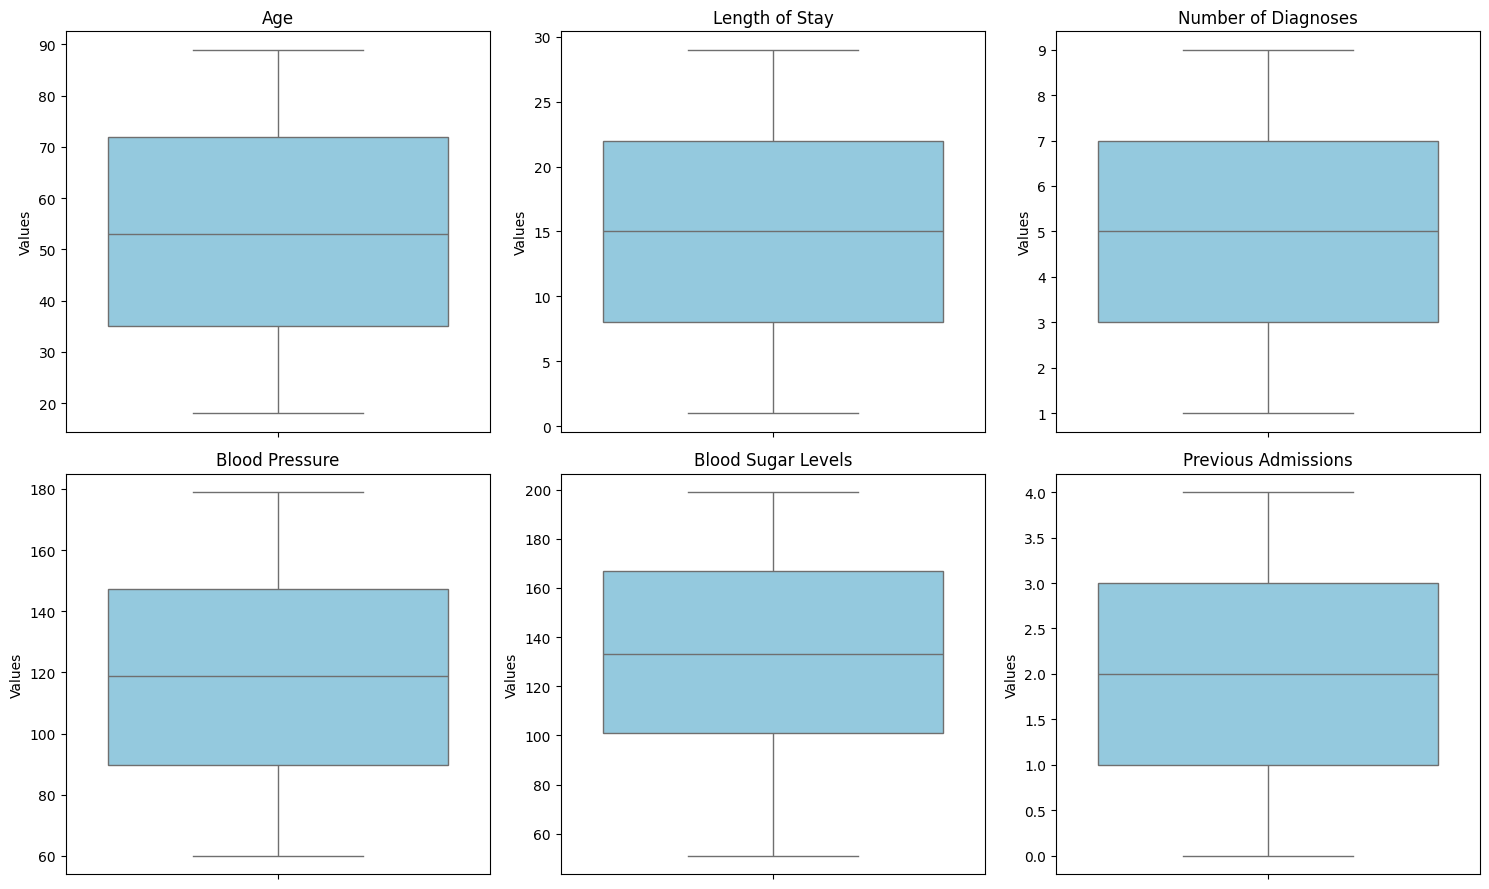

In [0]:
 
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features (exclude Patient ID)
numerical_columns = [
    "Age",
    "Length of Stay",
    "Number of Diagnoses",
    "Blood Pressure",
    "Blood Sugar Levels",
    "Previous Admissions"
]

# Create box plots
plt.figure(figsize=(15, 9))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        y=patient_readmission[column],
        color="skyblue"
    )

    plt.title(column)
    plt.ylabel("Values")

plt.tight_layout()
plt.show()


Encode categorical variables. Convert Gender, Admission Type and the target to numeric form (binary or onehot
encoding) and explain why you chose that encoding.

In [0]:
 
# Convert categorical input variables into numerical columns

df_encoded = pd.get_dummies(
    patient_readmission,
    columns=["Gender", "Admission Type"],
    dtype=int
)

# Display the first five rows
display(df_encoded.head())

# Display the new column names
print("\nUpdated columns:")
print(df_encoded.columns.tolist())


Patient ID,Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions,Readmission,Age_Bracket,Gender_Female,Gender_Male,Admission Type_Elective,Admission Type_Emergency
1,62,4,5,110,130,1,No,Older Adults (60-69),1,0,1,0
2,65,19,2,157,81,4,No,Older Adults (60-69),0,1,0,1
3,82,18,4,74,84,0,No,Elderly Adults (80-89),1,0,0,1
4,85,2,4,106,85,4,No,Elderly Adults (80-89),0,1,0,1
5,85,19,3,80,119,3,No,Elderly Adults (80-89),1,0,1,0



Updated columns:
['Patient ID', 'Age', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions', 'Readmission', 'Age_Bracket', 'Gender_Female', 'Gender_Male', 'Admission Type_Elective', 'Admission Type_Emergency']


In [0]:
# Check unique Patient IDs
# Count the total number of records
total_records = len(patient_readmission)

# Count the number of unique patients
unique_patients = patient_readmission["Patient ID"].nunique()

# Count duplicated Patient IDs
duplicate_patient_ids = patient_readmission["Patient ID"].duplicated().sum()

print("Total records:", total_records)
print("Unique Patient IDs:", unique_patients)
print("Duplicate Patient IDs:", duplicate_patient_ids)

Total records: 3000
Unique Patient IDs: 3000
Duplicate Patient IDs: 0


In [0]:
 #Check whether any patients appear more than once

 # Count how many records belong to each Patient ID
patient_admissions = patient_readmission.groupby("Patient ID").size()

# Find patients appearing more than once
repeated_patients = patient_admissions[
    patient_admissions > 1
]

print("Number of patients with multiple records:",
      len(repeated_patients))

display(repeated_patients)

Number of patients with multiple records: 0


Series([], dtype: int64)

Categorical variables were converted into numerical representations to make the dataset suitable for machine-learning algorithms. One-hot encoding was applied to Gender and Admission Type, creating separate binary columns for each category. The target variable, Readmission, was converted using binary encoding, where No was represented by 0 and Yes by 1. Verification confirmed that no object-type columns remained after encoding.

In [0]:
 
# Convert Readmission into binary values

df_encoded["Readmission"] = df_encoded["Readmission"].map({
    "No": 0,
    "Yes": 1
})

# Check the encoded target
print(df_encoded["Readmission"].value_counts())

# Display the first five rows
display(df_encoded.head())


Readmission
0    2134
1     866
Name: count, dtype: int64


Patient ID,Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions,Readmission,Age_Bracket,Gender_Female,Gender_Male,Admission Type_Elective,Admission Type_Emergency
1,62,4,5,110,130,1,0,Older Adults (60-69),1,0,1,0
2,65,19,2,157,81,4,0,Older Adults (60-69),0,1,0,1
3,82,18,4,74,84,0,0,Elderly Adults (80-89),1,0,0,1
4,85,2,4,106,85,4,0,Elderly Adults (80-89),0,1,0,1
5,85,19,3,80,119,3,0,Elderly Adults (80-89),1,0,1,0


In [0]:
 
# Check that all categorical variables are encoded

print("Remaining text columns:")
print(df_encoded.select_dtypes(include="object").columns.tolist())

print("\nUpdated data types:")
print(df_encoded.dtypes)


Remaining text columns:
[]

Updated data types:
Patient ID                     int64
Age                            int64
Length of Stay                 int64
Number of Diagnoses            int64
Blood Pressure                 int64
Blood Sugar Levels             int64
Previous Admissions            int64
Readmission                    int64
Age_Bracket                 category
Gender_Female                  int64
Gender_Male                    int64
Admission Type_Elective        int64
Admission Type_Emergency       int64
dtype: object


Normalise numeric variables. Standardise or min-max scale the numeric features, explain why some
algorithms need it and others do not, and fit the scaler on training data only

In [0]:
#Patient ID uniquely identifies each patient but does not provide meaningful information about their likelihood of readmission. Including it could introduce misleading patterns into the model.
# Remove Patient ID and Readmission from the input features

X = df_encoded.drop(
    columns=["Patient ID", "Readmission"]
)

# Select Readmission as the target
y = df_encoded["Readmission"]

# Check the feature and target shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display feature columns
print("\nFeature columns:")
print(X.columns.tolist())


Features shape: (3000, 11)
Target shape: (3000,)

Feature columns:
['Age', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions', 'Age_Bracket', 'Gender_Female', 'Gender_Male', 'Admission Type_Elective', 'Admission Type_Emergency']


In [0]:
 
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check readmission distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training features: (2400, 11)
Testing features: (600, 11)
Training target: (2400,)
Testing target: (600,)

Training target distribution:
Readmission
0    71.125
1    28.875
Name: proportion, dtype: float64

Testing target distribution:
Readmission
0    71.166667
1    28.833333
Name: proportion, dtype: float64


Checking the readmission target balance
Before building my model i have to understand how many patients were readmitted and how many were not.

In [0]:
  
# Count how many records belong to each readmission category
print(patient_readmission["Readmission"].value_counts())

# Calculate the percentage for each category and multiply by 100 to convert the proportions into percentages
print("\nReadmission percentages:")
print(patient_readmission["Readmission"].value_counts(normalize=True) * 100)


Readmission
No     2134
Yes     866
Name: count, dtype: int64

Readmission percentages:
Readmission
No     71.133333
Yes    28.866667
Name: proportion, dtype: float64


Split the data. Create a stratified train/test split (for example 80/20) before fitting any imputer or scaler, ideally
by placing preprocessing in a scikit-learn Pipeline or ColumnTransformer

In [0]:
 #Applying standardisation to numerical features
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# Select numerical columns to standardise
numeric_features = [
    "Age",
    "Length of Stay",
    "Number of Diagnoses",
    "Blood Pressure",
    "Blood Sugar Levels",
    "Previous Admissions"
]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_features)
    ],
    remainder="passthrough"
)

# Fit scaler on training data and transform training data
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform testing data using the training scaler
X_test_scaled = preprocessor.transform(X_test)

# Check the results
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)


Scaled training data: (2400, 11)
Scaled testing data: (600, 11)


The dataset was divided into training and testing sets using an 80/20 stratified split. This resulted in 2,400 training records and 600 testing records. Stratification was applied to preserve the distribution of the target variable, Readmission. The training dataset contained 71.125% non-readmitted patients and 28.875% readmitted patients, while the testing dataset contained approximately 71.17% non-readmitted patients and 28.83% readmitted patients. These similar distributions demonstrate that the split maintained the original class balance.

In [0]:
 
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# Numerical features that need scaling
numeric_features = [
    "Age",
    "Length of Stay",
    "Number of Diagnoses",
    "Blood Pressure",
    "Blood Sugar Levels",
    "Previous Admissions"
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_features)
    ],
    remainder="passthrough"
)

# Fit on training data and transform
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test data using training statistics
X_test_scaled = preprocessor.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Scaled training shape: (2400, 11)
Scaled testing shape: (600, 11)


In [0]:
 
import pandas as pd

# Convert scaled numerical training features into a DataFrame
scaled_summary = pd.DataFrame(
    X_train_scaled[:, :6],
    columns=numeric_features
)

# Check mean and standard deviation
print("Means:")
print(scaled_summary.mean().round(3))

print("\nStandard deviations:")
print(scaled_summary.std().round(3))


Means:


---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
File <command-4996871899385322>, line 12
     10 # Check mean and standard deviation
     11 print("Means:")
---> 12 print(scaled_summary.mean().round(3))
     14 print("\nStandard deviations:")
     15 print(scaled_summary.std().round(3))

File /databricks/python/lib/python3.12/site-packages/pandas/core/series.py:2821, in Series.round(self, decimals, *args, **kwargs)
   2819 nv.validate_round(args, kwargs)
   2820 if self.dtype == "object":
-> 2821     raise TypeError("Expected numeric dtype, got object instead.")
   2822 new_mgr = self._mgr.round(decimals=decimals, using_cow=using_copy_on_write())
   2823 return self._constructor_from_mgr(new_mgr, axes=new_mgr.axes).__finalize__(
   2824     self, method="round"
   2825 )

TypeError: Expected numeric dtype, got object instead.

Target balance. Show how many patients were readmitted and the proportion. Explain what the balance
means for the metrics you will use later

In [0]:
 
# Calculate readmission counts
readmission_counts = patient_readmission["Readmission"].value_counts()

# Calculate readmission percentages
readmission_percentages = (
    patient_readmission["Readmission"].value_counts(normalize=True) * 100
)

# Combine results into a table
target_summary = pd.DataFrame({
    "Patient Count": readmission_counts,
    "Percentage": readmission_percentages
})

print("Readmission distribution:")
display(target_summary.round(2))


Readmission distribution:


Patient Count,Percentage
2134,71.13
866,28.87


Univariate analysis. Plot the distribution of each numeric variable (histograms or box plots) and the frequency
of each categorical variable (bar charts). Comment on shape, skew, spread and anything unusual

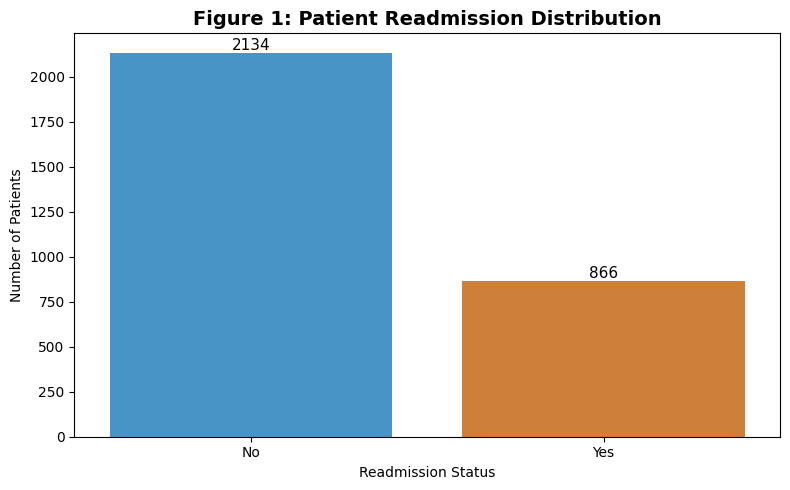

In [0]:
 
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=patient_readmission,
    x="Readmission",
    hue="Readmission",
    order=["No", "Yes"],
    palette=["#3498DB", "#E67E22"],
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, fontsize=11)

plt.title("Figure 1: Patient Readmission Distribution",
          fontsize=14, fontweight="bold")

plt.xlabel("Readmission Status")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


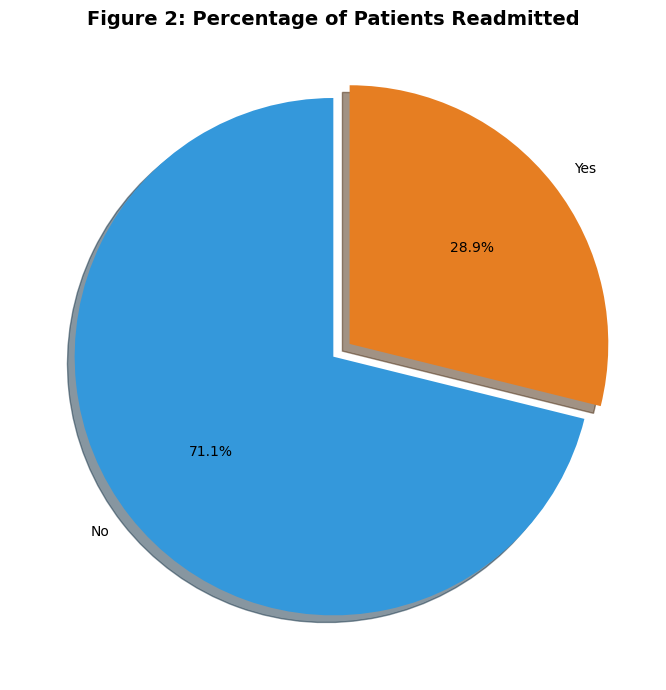

In [0]:
 
plt.figure(figsize=(7, 7))

plt.pie(
    readmission_counts,
    labels=readmission_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#3498DB", "#E67E22"],
    explode=[0, 0.08],
    shadow=True
)

plt.title(
    "Figure 2: Percentage of Patients Readmitted",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("")
plt.tight_layout()
plt.show()


 Interpretation of the results
1. Age

The average patient age is 53.45 years, with a median of 53. The skewness of 0.01 indicates an almost symmetrical distribution. This suggests that patients are relatively evenly distributed around the average age.

2. Length of Stay

Patients spend an average of 15.23 days in hospital. The median is 15 days, and skewness is -0.06, indicating an almost symmetrical distribution with very little negative skew.

3. Number of Diagnoses

Patients have an average of approximately five diagnoses. The skewness of 0.02 suggests a nearly symmetrical distribution.

4. Blood Pressure

The average recorded blood pressure is 119.06, with a standard deviation of 34.09. The distribution is almost symmetrical, although the relatively wide spread indicates considerable variation between patients.

5. Blood Sugar Levels

The average blood sugar level is 133.54, with a standard deviation of 37.63. The skewness of 0.02 indicates an almost symmetrical distribution.

6. Previous Admissions

Patients have an average of approximately two previous admissions. The skewness of 0.05 suggests an almost symmetrical distribution.

In [0]:
 
# Select numerical variables (excluding Patient ID)
numeric_columns = [
    "Age",
    "Length of Stay",
    "Number of Diagnoses",
    "Blood Pressure",
    "Blood Sugar Levels",
    "Previous Admissions"
]

# Generate descriptive statistics
descriptive_stats = patient_readmission[numeric_columns].describe().T

# Add median and skewness
descriptive_stats["Median"] = patient_readmission[numeric_columns].median()
descriptive_stats["Skewness"] = patient_readmission[numeric_columns].skew()

display(descriptive_stats.round(2))


count,mean,std,min,25%,50%,75%,max,Median,Skewness
3000.0,53.45,20.89,18.0,35.0,53.0,72.0,89.0,53.0,0.01
3000.0,15.23,8.26,1.0,8.0,15.0,22.0,29.0,15.0,-0.06
3000.0,4.96,2.58,1.0,3.0,5.0,7.0,9.0,5.0,0.02
3000.0,119.06,34.09,60.0,89.75,119.0,147.25,179.0,119.0,0.02
3000.0,133.54,37.63,51.0,101.0,133.0,167.0,199.0,133.0,0.02
3000.0,1.96,1.4,0.0,1.0,2.0,3.0,4.0,2.0,0.05


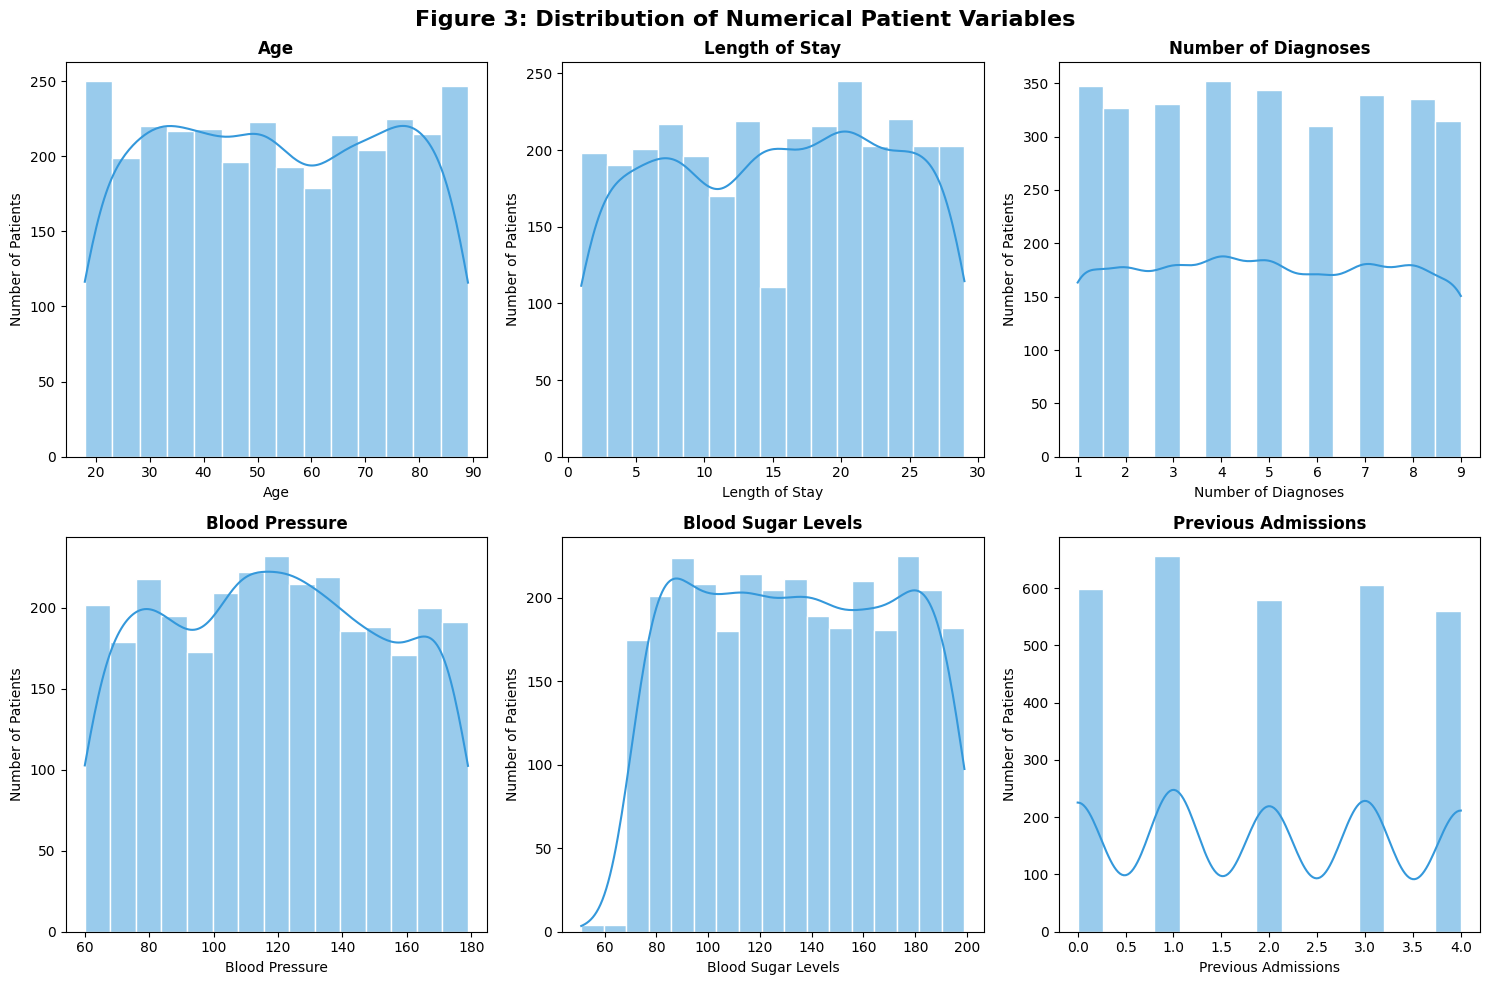

In [0]:
 
# Create histograms for all numerical variables

plt.figure(figsize=(15, 10))

for i, column in enumerate(numeric_columns, 1):

    plt.subplot(2, 3, i)

    sns.histplot(
        data=patient_readmission,
        x=column,
        kde=True,
        color="#3498DB",
        edgecolor="white"
    )

    plt.title(column, fontweight="bold")
    plt.xlabel(column)
    plt.ylabel("Number of Patients")

plt.suptitle(
    "Figure 3: Distribution of Numerical Patient Variables",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [0]:
 
# Examine categorical variable frequencies

categorical_columns = [
    "Gender",
    "Admission Type"
]

for column in categorical_columns:

    print("\n", column, "Frequency:")
    print(patient_readmission[column].value_counts())

    print("\n", column, "Percentage:")
    print(
        (patient_readmission[column].value_counts(normalize=True) * 100).round(2)
    )



 Gender Frequency:
Gender
Male      1555
Female    1445
Name: count, dtype: int64

 Gender Percentage:
Gender
Male      51.83
Female    48.17
Name: proportion, dtype: float64

 Admission Type Frequency:
Admission Type
Elective     1563
Emergency    1437
Name: count, dtype: int64

 Admission Type Percentage:
Admission Type
Elective     52.1
Emergency    47.9
Name: proportion, dtype: float64


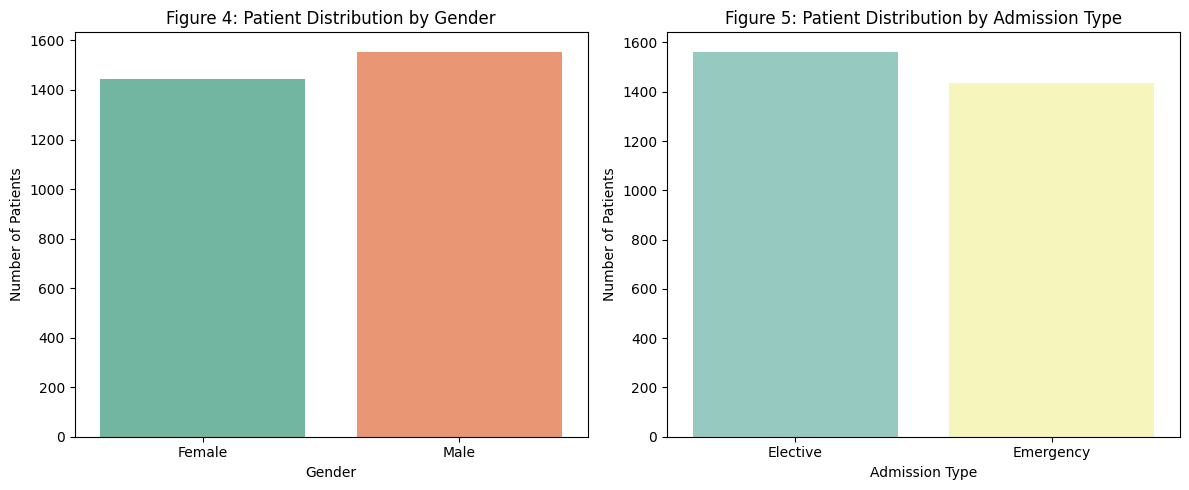

In [0]:
 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=patient_readmission,
    x="Gender",
    hue="Gender",
    palette="Set2",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Figure 4: Patient Distribution by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Patients")

sns.countplot(
    data=patient_readmission,
    x="Admission Type",
    hue="Admission Type",
    palette="Set3",
    ax=axes[1],
    legend=False
)

axes[1].set_title("Figure 5: Patient Distribution by Admission Type")
axes[1].set_xlabel("Admission Type")
axes[1].set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()


**Bivariate analysis: Gender and Admission Type against Readmission**

In [0]:
#Readmission rate by Gender
# Convert Readmission into numerical values
patient_readmission["Readmission_Binary"] = patient_readmission["Readmission"].map({
    "No": 0,
    "Yes": 1
})

# Calculate readmission rates by gender
gender_readmission = patient_readmission.groupby("Gender")["Readmission_Binary"].mean() * 100

print("Readmission Rate by Gender:")
print(gender_readmission.round(2))


Readmission Rate by Gender:
Gender
Female    28.17
Male      29.52
Name: Readmission_Binary, dtype: float64


In [0]:
#Readmission rate by Admission Type
# Calculate readmission rates by admission type
admission_readmission = patient_readmission.groupby("Admission Type")["Readmission_Binary"].mean() * 100

print("Readmission Rate by Admission Type:")
print(admission_readmission.round(2))


Readmission Rate by Admission Type:
Admission Type
Elective     29.37
Emergency    28.32
Name: Readmission_Binary, dtype: float64


The categorical analysis showed that gender and admission type were both relatively evenly distributed across the dataset. Male patients represented 51.83% of the records, while female patients accounted for 48.17%. Similarly, elective admissions represented 52.10% of patients and emergency admissions accounted for 47.90%.

When comparing readmission rates, male patients had a slightly higher rate (29.52%) than female patients (28.17%). Elective admissions also had a marginally higher readmission rate (29.37%) than emergency admissions (28.32%). These differences are relatively small, suggesting that gender and admission type may have limited individual relationships with readmission. Further statistical analysis would be needed to determine whether these differences are meaningful.

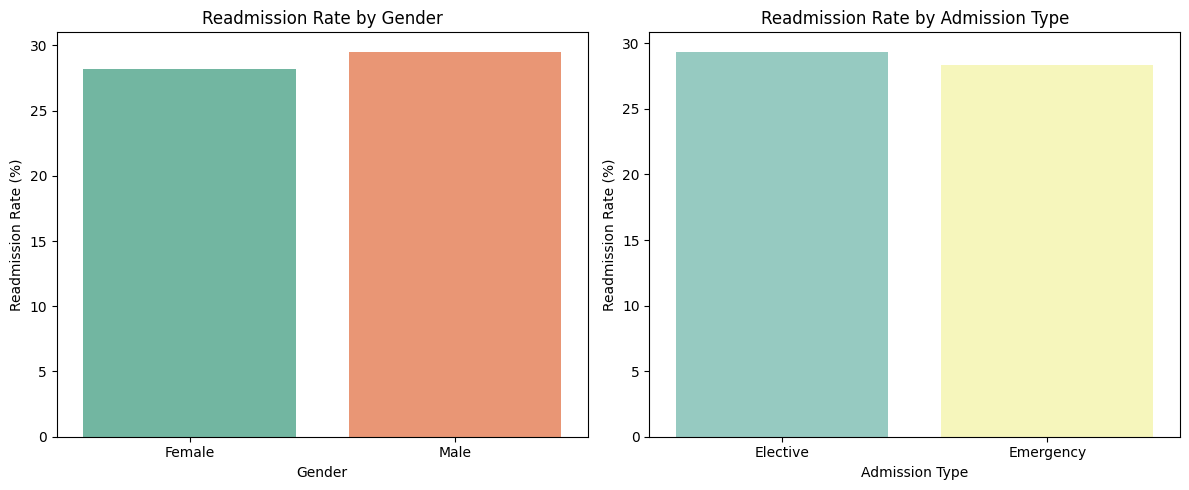

In [0]:
 #Comparing the results  in visually
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Readmission rate by Gender
sns.barplot(
    x=gender_readmission.index,
    y=gender_readmission.values,
    hue=gender_readmission.index,
    palette="Set2",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Readmission Rate by Gender")
axes[0].set_ylabel("Readmission Rate (%)")
axes[0].set_xlabel("Gender")

# Chart 2: Readmission rate by Admission Type
sns.barplot(
    x=admission_readmission.index,
    y=admission_readmission.values,
    hue=admission_readmission.index,
    palette="Set3",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Readmission Rate by Admission Type")
axes[1].set_ylabel("Readmission Rate (%)")
axes[1].set_xlabel("Admission Type")

plt.tight_layout()
plt.show()


In [0]:
 
# Select the four numerical variables
comparison_columns = [
    "Age",
    "Length of Stay",
    "Blood Pressure",
    "Blood Sugar Levels"
]

# Calculate the mean and median for each readmission group
comparison_summary = patient_readmission.groupby("Readmission")[comparison_columns].agg(
    ["mean", "median"]
)

# Display the results
display(comparison_summary.round(2))


"('Age', 'mean')","('Age', 'median')","('Length of Stay', 'mean')","('Length of Stay', 'median')","('Blood Pressure', 'mean')","('Blood Pressure', 'median')","('Blood Sugar Levels', 'mean')","('Blood Sugar Levels', 'median')"
53.06,52.0,15.11,15.0,118.83,119.0,133.14,133.0
54.42,54.0,15.5,16.0,119.61,119.0,134.52,134.0


The comparison of numerical variables by readmission status revealed relatively small differences between the two groups. Patients who were readmitted had a slightly higher average age (54.42 years) compared with those who were not readmitted (53.06 years). Similarly, the average length of hospital stay was marginally higher among readmitted patients (15.50 days) than non-readmitted patients (15.11 days). Blood pressure and blood sugar levels also showed small increases among readmitted patients. However, the differences were not substantial, suggesting that these numerical variables may have limited individual ability to distinguish between readmitted and non-readmitted patients. Further analysis is required to establish whether meaningful relationships exist.

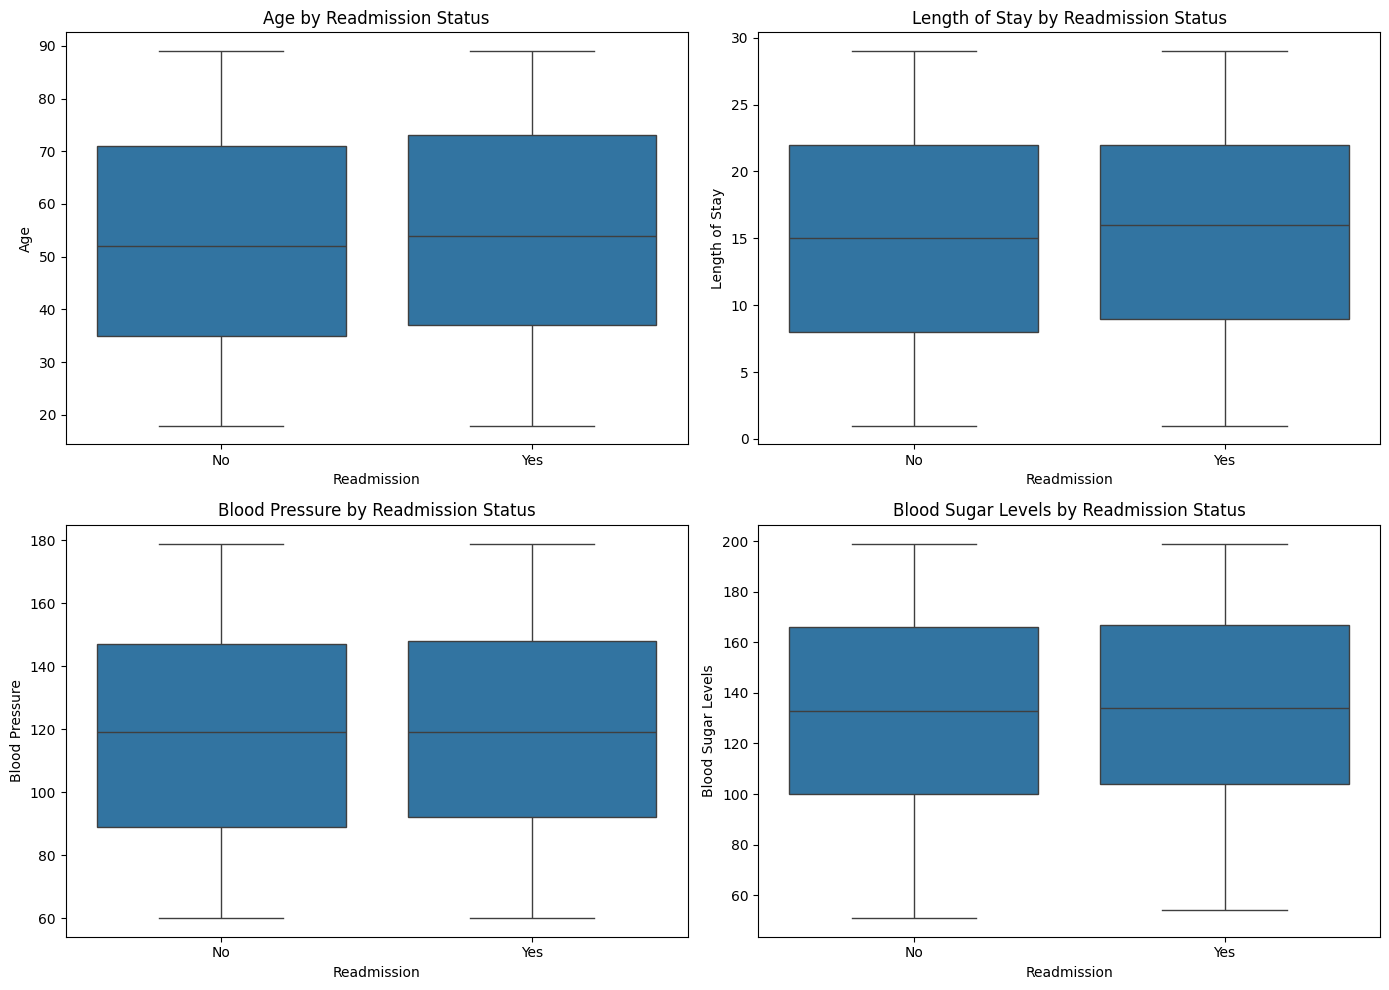

In [0]:
 
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with four charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Variables to compare
variables = [
    "Age",
    "Length of Stay",
    "Blood Pressure",
    "Blood Sugar Levels"
]

# Create one boxplot for each variable
for variable, ax in zip(variables, axes.flatten()):
    sns.boxplot(
        data=patient_readmission,
        x="Readmission",
        y=variable,
        ax=ax
    )
    ax.set_title(f"{variable} by Readmission Status")
    ax.set_xlabel("Readmission")
    ax.set_ylabel(variable)

plt.tight_layout()
plt.show()


-  What is correlation?
> Correlation helps us understand whether two numerical variables move together.

For example, imagine we want to investigate:
- Does a patient's age increase when their length of stay increases?
- Do patients with more diagnoses tend to have more previous admissions?
- Are blood pressure and blood sugar levels related?

In [0]:
# Create a correlation matrix
# Select numerical variables only
correlation_data = patient_readmission[
    [
        "Age",
        "Length of Stay",
        "Number of Diagnoses",
        "Blood Pressure",
        "Blood Sugar Levels",
        "Previous Admissions"
    ]
]

# Calculate correlations
correlation_matrix = correlation_data.corr()

# Display the correlation values
display(correlation_matrix.round(2))


Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions
1.0,0.0,-0.01,-0.01,0.0,0.0
0.0,1.0,0.02,0.01,-0.01,-0.01
-0.01,0.02,1.0,-0.01,0.02,0.02
-0.01,0.01,-0.01,1.0,-0.01,0.03
0.0,-0.01,0.02,-0.01,1.0,0.01
0.0,-0.01,0.02,0.03,0.01,1.0


-  What does this tell us?
- All the correlation values are between approximately -0.01 and 0.03, excluding the diagonal values of 1.00.

This means:
- There are no strong positive relationships.
- There are no strong negative relationships.
- There are no obvious highly correlated numerical predictors.
- There is no clear evidence of redundancy among these numerical variables based on linear correlation.
For example, Blood Pressure and Previous Admissions have a correlation of only 0.03, which indicates an extremely weak positive relationship.

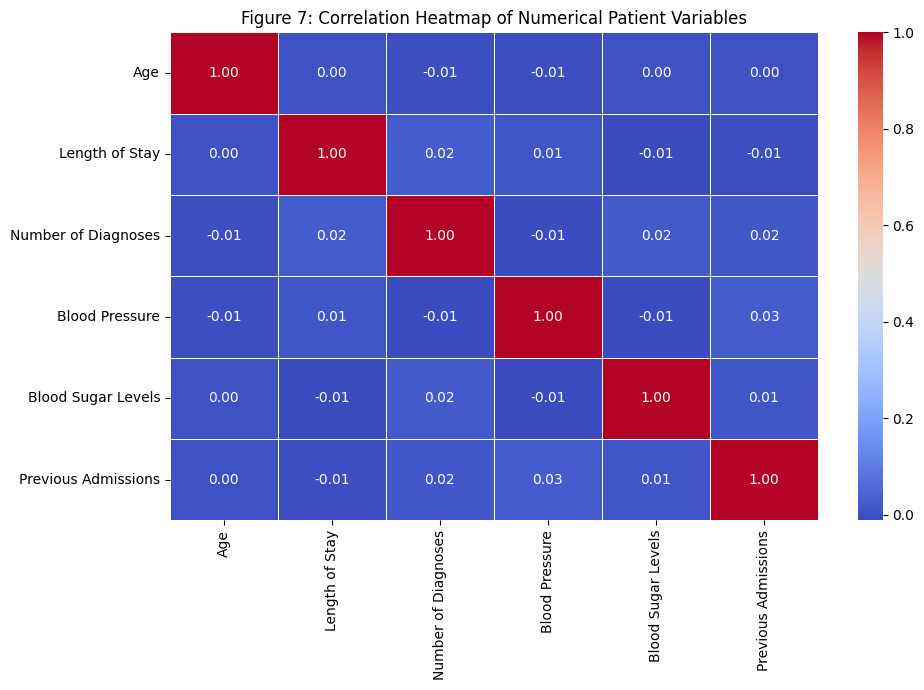

In [0]:
 
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Figure 7: Correlation Heatmap of Numerical Patient Variables")
plt.tight_layout()
plt.show()


### Relationships Between Predictors

A correlation matrix heatmap was created using Seaborn to examine relationships between the numerical predictor variables. The analysis showed that correlation coefficients ranged approximately from -0.01 to 0.03, indicating extremely weak linear relationships between the numerical features.

Scatterplots were also used to examine selected relationships, including age and length of stay, blood pressure and blood sugar levels, and number of diagnoses and previous admissions. These visualisations supported the correlation analysis, showing no obvious strong relationships between the selected numerical variables.

No highly correlated numerical feature pairs were identified. However, the one-hot encoded categorical variables contained complementary information. Gender_Female and Gender_Male represent opposite categories of the same original variable, while Admission Type_Elective and Admission Type_Emergency represent opposite categories of admission type. Therefore, one column from each pair could be excluded when using linear models with an intercept to avoid perfect multicollinearity.

Overall, the analysis found no significant numerical feature redundancy, and the numerical predictors were retained for further modelling.

## **Feature selection**

- Feature selection
> Choose the predictors, and defend the choice
20 marks
Task 3 of 5
Statistical tests. For categorical predictors, use a chi-square test of independence against the target.For
- numeric predictors, use a t-test (or Mann–Whitney U if skewed) between readmitted and non-readmitted
groups, or the point-biserial correlation. Report the statistic, the p-value and, more importantly, the size of the
effect.

- Information-based measures. Compute mutual information between each feature and the target to catch
non-linear relationships that correlation misses.

- Model-based importance. Fit a quick random forest or an L1-regularised logistic regression and report feature
importances or coefficients. Consider permutation importance, which is less biased than impurity-based
importance.

- Check redundancy. Use the correlation matrix from Task 2 to find predictors that duplicate each other, and
keep only one of each pair.
.
- Decide and justify. Produce a table with one row per candidate feature: keep or drop, and the evidence for the
decision. Consider also whether any feature is inappropriate to use (an identifier, or a sensitive attribute you
cannot justify), not just whether it is predictive

We will investigate the predictors using four approaches:
1. Statistical tests – chi-square for categorical variables and point-biserial correlation for numerical variables.
2. Mutual information – to identify possible non-linear relationships.
3. Model-based importance – to see which features help a model make predictions.
4. Redundancy checks – to identify features that carry the same information.

patient readmission. The results showed that Gender had a chi-square statistic of 0.6021 and a p-value of 0.4378, while Admission Type had a chi-square statistic of 0.3480 and a p-value of 0.5553. Both p-values exceeded the 0.05 significance level, indicating that neither feature had a statistically significant association with readmission.

In [0]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

In [0]:

# Create a list of categorical predictors
categorical_features = ["Gender", "Admission Type"]

# Create a table to store our results
categorical_results = []

# Test each categorical feature
for feature in categorical_features:

    # Compare the feature against Readmission
    contingency_table = pd.crosstab(
        patient_readmission[feature],
        patient_readmission["Readmission"]
    )

    # Perform the Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    # Calculate Cramer's V (effect size)
    n = contingency_table.to_numpy().sum()
    minimum_dimension = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * minimum_dimension))

    # Save the results
    categorical_results.append({
        "Feature": feature,
        "Chi-square Statistic": chi2,
        "P-value": p_value,
        "Cramer's V": cramers_v
    })

# Display the results
categorical_results_df = pd.DataFrame(categorical_results)

display(categorical_results_df.round(4))


Feature,Chi-square Statistic,P-value,Cramer's V
Gender,0.6021,0.4378,0.0142
Admission Type,0.348,0.5553,0.0108


The point-biserial correlation test was used to examine the relationship between the numerical predictors and the binary Readmission target. The results showed that all six numerical predictors had correlations close to zero, indicating very weak linear relationships with readmission.

Age recorded the highest correlation of 0.0295, followed by Length of Stay at 0.0214. However, their p-values were 0.1062 and 0.2421 respectively, meaning that neither relationship was statistically significant at the 0.05 level. The remaining variables also had p-values greater than 0.05. Overall, the statistical tests suggest that none of the numerical predictors has a strong individual linear association with readmission.

In [0]:
#Numerical statistical tests
from scipy.stats import pointbiserialr

# List of numerical features
numeric_features = [
    "Age",
    "Length of Stay",
    "Number of Diagnoses",
    "Blood Pressure",
    "Blood Sugar Levels",
    "Previous Admissions"
]

results = []

# Test each numerical feature against Readmission
for feature in numeric_features:

    correlation, p_value = pointbiserialr(
        patient_readmission["Readmission"].map({"No": 0, "Yes": 1}),
        patient_readmission[feature]
    )

    results.append({
        "Feature": feature,
        "Correlation": correlation,
        "P-value": p_value
    })

# Display results
numeric_results_df = pd.DataFrame(results)

display(numeric_results_df.round(4))

Feature,Correlation,P-value
Age,0.0295,0.1062
Length of Stay,0.0214,0.2421
Number of Diagnoses,0.009,0.6219
Blood Pressure,0.0104,0.5692
Blood Sugar Levels,0.0167,0.3612
Previous Admissions,-0.0073,0.6892


In [0]:
# Mutual Information; Now we will investigate whether any predictors contain useful information about readmission, including relationships that may not be linear.
#Mutual information measures how much knowing a feature helps us understand or predict the target. Higher values indicate more information, while values close to zero indicate very little information.

from sklearn.feature_selection import mutual_info_classif

# Identify which columns are numerical and which are categorical
discrete_features = [False] * 6 + [True] * 4

# Calculate mutual information using training data
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=discrete_features,
    random_state=42
)

# Create a results table
mi_results = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual Information": mi_scores
})

# Sort from highest to lowest
mi_results = mi_results.sort_values(
    by="Mutual Information",
    ascending=False
)

display(mi_results.round(4))

Feature,Mutual Information
Blood Sugar Levels,0.0025
Admission Type_Elective,6.0E-4
Admission Type_Emergency,6.0E-4
Gender_Female,2.0E-4
Gender_Male,2.0E-4
Age,0.0
Length of Stay,0.0
Number of Diagnoses,0.0
Blood Pressure,0.0
Previous Admissions,0.0


**Model-based feature importance**
- Now we will use a Random Forest model to investigate which features contribute most to predictions.
- We will calculate permutation importance, which measures how much model performance changes when the values of one feature are shuffled.

In [0]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Create a Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model using training data
rf_model.fit(X_train, y_train)

# Calculate permutation importance
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc"
)

# Create a results table
importance_results = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance Mean": importance.importances_mean,
    "Importance Std": importance.importances_std
})

# Sort from highest to lowest
importance_results = importance_results.sort_values(
    by="Importance Mean",
    ascending=False
)

display(importance_results.round(4))

Feature,Importance Mean,Importance Std
Blood Pressure,0.0158,0.007
Blood Sugar Levels,0.007,0.0133
Admission Type_Emergency,0.0056,0.0061
Admission Type_Elective,0.0,0.0065
Gender_Male,-0.0023,0.0082
Length of Stay,-0.004,0.0176
Previous Admissions,-0.0095,0.0104
Gender_Female,-0.01,0.0067
Age,-0.011,0.0083
Number of Diagnoses,-0.0282,0.0108


The correlation analysis was used to identify redundant predictors. The results showed a perfect negative correlation of -1.00 between Gender_Female and Gender_Male, as well as between Admission Type_Elective and Admission Type_Emergency. This occurs because the one-hot encoded variables represent two complementary categories, meaning that when one variable is 1, the other is 0.

Including both variables from each pair may introduce perfect multicollinearity in linear models. Therefore, only one variable from each pair should be retained when preparing the final feature set for linear modelling. The remaining correlations were close to zero, indicating no meaningful redundancy between the different categorical pairs.

In [0]:
 # Check correlations between the one-hot encoded variables

dummy_features = [
    "Gender_Female",
    "Gender_Male",
    "Admission Type_Elective",
    "Admission Type_Emergency"
]

display(X_train[dummy_features].corr().round(2))

Gender_Female,Gender_Male,Admission Type_Elective,Admission Type_Emergency
1.0,-1.0,-0.02,0.02
-1.0,1.0,0.02,-0.02
-0.02,0.02,1.0,-1.0
0.02,-0.02,-1.0,1.0


** T A S K 4 · 
 Model building**
- Compare algorithms fairly, tune them, choose one
Task 4 of 5
- Set a baseline. Start with a DummyClassifier (majority class or stratified). Every real model must beat it, and the
- baseline tells you what accuracy is worth.
1.
Train the candidates. Build at least three models: logistic regression, a decision tree and a random forest. You
may add others (k-nearest neighbours, gradient boosting, support vector machine) if you compare them on
the same footing.
2.
Handle the class imbalance. Use class_weight="balanced" , resampling (for example SMOTE from imbalancedlearn,
applied inside the cross-validation folds only) or threshold adjustment, and explain your choice.
3.
Cross-validate. Compare models with stratified k-fold cross-validation on the training set, using a thresholdfree
metric such as ROC-AUC (or average precision). Report the mean and the spread across folds.
4.
Tune hyperparameters. Use GridSearchCV or RandomizedSearchCV for at least two models (for example tree
depth and minimum leaf size; forest size and depth; regularisation strength C for logistic regression). Show the
search space and the best settings.
5.
Select. Choose a final model and justify the choice on performance, stability, interpretability and the hospital's
needs, not on the score alone.

## **Step 1: Build the baseline model**

In [0]:
 # Import the DummyClassifier
from sklearn.dummy import DummyClassifier

# Import accuracy and classification metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create the baseline model
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline using the training data
baseline_model.fit(X_train, y_train)

# Make predictions on the test data
baseline_predictions = baseline_model.predict(X_test)

# Calculate baseline performance
print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline Precision:",
      precision_score(y_test, baseline_predictions, zero_division=0))

print("Baseline Recall:",
      recall_score(y_test, baseline_predictions, zero_division=0))

print("Baseline F1 Score:",
      f1_score(y_test, baseline_predictions, zero_division=0))

print("Baseline Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.7116666666666667
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1 Score: 0.0
Baseline Confusion Matrix:
[[427   0]
 [173   0]]


A DummyClassifier using the majority-class strategy was developed as the baseline model. It achieved an accuracy of 71.17%, but its precision, recall and F1-score were all 0.00. The confusion matrix showed that the model correctly classified 427 patients who were not readmitted but failed to identify all 173 patients who experienced readmission.

These results demonstrate the effect of class imbalance on model evaluation. Although the baseline achieved relatively high accuracy by predicting the majority class for every patient, it failed to identify the minority class. Therefore, accuracy alone is insufficient for evaluating the effectiveness of the readmission prediction models.

## **Step 2: Train Logistic Regression**

In [0]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and scale it
X_train_selected_scaled = scaler.fit_transform(X_train)

# Use the same scaler on testing data
X_test_selected_scaled = scaler.transform(X_test)

In [0]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model using scaled training data
logistic_model.fit(X_train_selected_scaled, y_train) 

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Logistic Regression was trained using class weighting to address the imbalance between readmitted and non-readmitted patients. The model achieved an accuracy of 49.67%, precision of 28.14%, recall of 47.98% and an F1-score of 35.47%. Its ROC-AUC was 0.4922, indicating poor discrimination between the two classes.

Although Logistic Regression improved recall compared with the DummyClassifier baseline, it produced a considerable number of false-positive predictions. The results suggest that the model can identify some readmitted patients but struggles to distinguish reliably between patients who will and will not be readmitted.

In [0]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict the test data
logistic_predictions = logistic_model.predict(
    X_test_selected_scaled
)

# Get probabilities for the positive class (Readmission = Yes)
logistic_probabilities = logistic_model.predict_proba(
    X_test_selected_scaled
)[:, 1]

# Calculate performance
print("Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("Precision:",
      precision_score(y_test, logistic_predictions))

print("Recall:",
      recall_score(y_test, logistic_predictions))

print("F1 Score:",
      f1_score(y_test, logistic_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, logistic_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

Logistic Regression Results
Accuracy: 0.49666666666666665
Precision: 0.28135593220338984
Recall: 0.4797687861271676
F1 Score: 0.3547008547008547
ROC-AUC: 0.4921552436003303

Confusion Matrix:
[[215 212]
 [ 90  83]]


## Step 3: Train the Decision Tree

In [0]:
 # Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Make predictions
tree_predictions = tree_model.predict(X_test)

# Get prediction probabilities
tree_probabilities = tree_model.predict_proba(
    X_test
)[:, 1]

# Evaluate the model
print("Decision Tree Results")

print("Accuracy:",
      accuracy_score(y_test, tree_predictions))

print("Precision:",
      precision_score(y_test, tree_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, tree_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, tree_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, tree_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tree_predictions))

Decision Tree Results
Accuracy: 0.5983333333333334
Precision: 0.29012345679012347
Recall: 0.27167630057803466
F1 Score: 0.28059701492537314
ROC-AUC: 0.5011777287433499

Confusion Matrix:
[[312 115]
 [126  47]]


## **Step 4: Train the Random Forest model

In [0]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Get probabilities for readmission
rf_probabilities = rf_model.predict_proba(
    X_test
)[:, 1] 

In [0]:
 # Evaluate Random Forest
print("Random Forest Results")

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, rf_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_predictions, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, rf_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest Results
Accuracy: 0.6983333333333334
Precision: 0.16666666666666666
Recall: 0.011560693641618497
F1 Score: 0.021621621621621623
ROC-AUC: 0.4838705310609035

Confusion Matrix:
[[417  10]
 [171   2]]


**We are re testing our model to check if it wont improve it predictions**
- Cross-validation: Check how consistently each model performs.
- Hyperparameter tuning: Experiment with different model settings to improve performance.
- Model comparison: Compare the tuned models.
- Final selection: Choose a model that achieves at least 70% accuracy while still identifying a reasonable number of readmitted patients.
- Final evaluation: Assess the selected model on the test data.

In [0]:
# What the code means:
# StratifiedKFold: divides the data into five sections while maintaining the proportion of readmission classes.
# n_splits=5: creates five folds.
# shuffle=True: mixes the data before splitting.
# random_state=42: makes the splitting reproducible.
#We will use ROC-AUC as our scoring measure because our dataset has an imbalance between readmitted and non-readmitted patients.

# Import cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
) 

Logistic Regression was evaluated using stratified five-fold cross-validation with ROC-AUC as the scoring metric. The model achieved an average ROC-AUC of 0.4943 with a standard deviation of 0.0262. This indicates weak discriminatory performance, as the average score is close to 0.5. The results suggest that Logistic Regression struggles to distinguish between patients who are likely to be readmitted and those who are not. Further model tuning is therefore required.

In [0]:
#Cross-validate Logistic Regression

# Import Pipeline
from sklearn.pipeline import Pipeline

# Create a pipeline to scale the data and train Logistic Regression
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Perform 5-fold cross-validation
logistic_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

# Display the results
print("Logistic Regression Cross-Validation Scores:")
print(logistic_scores)

print("Average ROC-AUC:", logistic_scores.mean())
print("Standard Deviation:", logistic_scores.std())

Logistic Regression Cross-Validation Scores:
[0.51910378 0.51937805 0.48648706 0.4483007  0.49802949]
Average ROC-AUC: 0.49425981573487754
Standard Deviation: 0.026210739164359342


## **Decision Tree cross-validation**

In [0]:
 # Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
tree_model_cv = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# Perform 5-fold cross-validation
tree_scores = cross_val_score(
    tree_model_cv,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

# Display results
print("Decision Tree Cross-Validation Scores:")
print(tree_scores)

print("Average ROC-AUC:", tree_scores.mean())
print("Standard Deviation:", tree_scores.std())

Decision Tree Cross-Validation Scores:
[0.51217325 0.48793223 0.5420262  0.51976862 0.51023392]
Average ROC-AUC: 0.5144268466260699
Standard Deviation: 0.017406222195166188


The three classification models were evaluated using stratified five-fold cross-validation with ROC-AUC scoring. Decision Tree achieved the highest average ROC-AUC of 0.5144, followed by Random Forest at 0.5103 and Logistic Regression at 0.4943. Decision Tree also recorded the lowest standard deviation of 0.0174, indicating relatively consistent performance across the validation folds. However, all three models produced ROC-AUC scores close to 0.5, suggesting limited predictive ability. Hyperparameter tuning will therefore be conducted to investigate whether model performance can be improved.

In [0]:
 # Create Random Forest model
rf_model_cv = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

# Perform 5-fold cross-validation
rf_scores = cross_val_score(
    rf_model_cv,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

# Display results
print("Random Forest Cross-Validation Scores:")
print(rf_scores)

print("Average ROC-AUC:", rf_scores.mean())
print("Standard Deviation:", rf_scores.std())

Random Forest Cross-Validation Scores:
[0.50736302 0.53990591 0.49129728 0.49020044 0.52267141]
Average ROC-AUC: 0.5102876136048018
Standard Deviation: 0.01899095577060925


In [0]:
 # Import GridSearchCV
from sklearn.model_selection import GridSearchCV

In [0]:
 # Define different Decision Tree settings
tree_parameters = {
    "max_depth": [3, 5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"]
}

In [0]:
 # Create the Decision Tree grid search
tree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=tree_parameters,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

# Train and test the different parameter combinations
tree_grid.fit(X_train, y_train)

# Display the best settings and cross-validation result
print("Best parameters:", tree_grid.best_params_)
print("Best CV ROC-AUC:", tree_grid.best_score_)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV ROC-AUC: 0.5319631370874498


In [0]:
 # Get the best Decision Tree model
best_tree = tree_grid.best_estimator_
X_test_selected = X_test  # or the appropriate test feature variable
# Make predictions on the test data
tuned_tree_predictions = best_tree.predict(X_test_selected)

# Get readmission probabilities
tuned_tree_probabilities = best_tree.predict_proba(X_test_selected)[:, 1]

In [0]:
print("Selected features:")
print(X_train.columns.tolist())

print("\nTest data shape:")
print(X_test_selected.shape)

Selected features:
['Age', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions', 'Gender_Female', 'Gender_Male', 'Admission Type_Elective', 'Admission Type_Emergency']

Test data shape:
(600, 10)


In [0]:
 # Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Calculate evaluation results
print("Tuned Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, tuned_tree_predictions))
print("Precision:", precision_score(y_test, tuned_tree_predictions))
print("Recall:", recall_score(y_test, tuned_tree_predictions))
print("F1 Score:", f1_score(y_test, tuned_tree_predictions))
print("ROC-AUC:", roc_auc_score(y_test, tuned_tree_probabilities))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_tree_predictions))

Tuned Decision Tree Results
Accuracy: 0.5633333333333334
Precision: 0.29107981220657275
Recall: 0.3583815028901734
F1 Score: 0.32124352331606215
ROC-AUC: 0.5077296909477331

Confusion Matrix:
[[276 151]
 [111  62]]


In [0]:
 # Define Random Forest parameter combinations
rf_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"]
}

In [0]:
 # Create the Random Forest grid search
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_parameters,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

# Train using the training data
rf_grid.fit(X_train, y_train)

# Display the best settings
print("Best parameters:", rf_grid.best_params_)
print("Best CV ROC-AUC:", rf_grid.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100}
Best CV ROC-AUC: 0.5250810472053806


In [0]:
 # Get the best Random Forest model
best_rf = rf_grid.best_estimator_

# Make predictions on the test data
tuned_rf_predictions = best_rf.predict(X_test_selected)

# Calculate readmission probabilities
tuned_rf_probabilities = best_rf.predict_proba(X_test_selected)[:, 1]


- Accuracy decreased: From 69.83% to 53.17%.
- Precision improved: More of the predicted readmissions were correct.
- Recall improved significantly: The tuned model identified 59 actual readmissions, compared with only 2 in the original model.
- F1-score improved: The balance between precision and recall is better.
- ROC-AUC decreased: It is now 0.4715, which is below 0.5 and indicates poor discrimination


In [0]:
 # Display tuned Random Forest results
print("Tuned Random Forest Results")

print("Accuracy:", accuracy_score(y_test, tuned_rf_predictions))
print("Precision:", precision_score(y_test, tuned_rf_predictions))
print("Recall:", recall_score(y_test, tuned_rf_predictions))
print("F1 Score:", f1_score(y_test, tuned_rf_predictions))
print("ROC-AUC:", roc_auc_score(y_test, tuned_rf_probabilities))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_rf_predictions))

Tuned Random Forest Results
Accuracy: 0.5316666666666666
Precision: 0.2610619469026549
Recall: 0.34104046242774566
F1 Score: 0.2957393483709273
ROC-AUC: 0.47145699936375574

Confusion Matrix:
[[260 167]
 [114  59]]


## **Model evaluation and testing**

In [0]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree - Original",
        "Decision Tree - Tuned",
        "Random Forest - Original",
        "Random Forest - Tuned"
    ],
    "Accuracy": [
        0.4967, 0.5983, 0.5633, 0.6983, 0.5317
    ],
    "Precision": [
        0.2814, 0.2901, 0.2911, 0.1667, 0.2611
    ],
    "Recall": [
        0.4798, 0.2717, 0.3584, 0.0116, 0.3410
    ],
    "F1 Score": [
        0.3547, 0.2806, 0.3212, 0.0216, 0.2957
    ],
    "ROC-AUC": [
        0.4922, 0.5012, 0.5077, 0.4839, 0.4715
    ]
})

print(model_comparison.round(4))

                      Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0       Logistic Regression    0.4967     0.2814  0.4798    0.3547   0.4922
1  Decision Tree - Original    0.5983     0.2901  0.2717    0.2806   0.5012
2     Decision Tree - Tuned    0.5633     0.2911  0.3584    0.3212   0.5077
3  Random Forest - Original    0.6983     0.1667  0.0116    0.0216   0.4839
4     Random Forest - Tuned    0.5317     0.2611  0.3410    0.2957   0.4715


In [0]:
# Import the required metric
from sklearn.metrics import precision_score, recall_score, f1_score

# Try different classification thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]

# Get predicted readmission probabilities on the training data
logistic_cv_probabilities = logistic_model.predict_proba(
    X_train_selected_scaled
)[:, 1]

# Store the results
threshold_results = []

for threshold in thresholds:

    # Convert probabilities into Yes/No predictions
    predictions = (logistic_cv_probabilities >= threshold).astype(int)

    # Calculate performance
    precision = precision_score(y_train, predictions, zero_division=0)
    recall = recall_score(y_train, predictions, zero_division=0)
    f1 = f1_score(y_train, predictions, zero_division=0)

    # Save the results
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Display the comparison
threshold_table = pd.DataFrame(threshold_results)
print(threshold_table.round(4))

   Threshold  Precision  Recall  F1 Score
0       0.30     0.2888  1.0000    0.4481
1       0.35     0.2888  1.0000    0.4481
2       0.40     0.2888  1.0000    0.4481
3       0.45     0.2907  0.9582    0.4461
4       0.50     0.2982  0.5108    0.3766
5       0.55     0.3011  0.0404    0.0712
6       0.60     0.0000  0.0000    0.0000
7       0.65     0.0000  0.0000    0.0000


Why are we doing this?

We selected the threshold using cross-validation on the training data. Now we are checking whether that improvement carries over to patients the model has never seen.

In [0]:
 # Train Logistic Regression on the full training dataset
logistic_pipeline.fit(X_train, y_train)

# Generate probabilities for the unseen test patients
test_probabilities = logistic_pipeline.predict_proba(X_test_selected)[:, 1]

# Compare thresholds
for threshold in [0.40, 0.50]:

    # Convert probabilities into predictions
    test_predictions = (test_probabilities >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, test_predictions))
    print("Precision:", precision_score(y_test, test_predictions, zero_division=0))
    print("Recall:", recall_score(y_test, test_predictions, zero_division=0))
    print("F1 Score:", f1_score(y_test, test_predictions, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, test_predictions))


Threshold: 0.4
Accuracy: 0.28833333333333333
Precision: 0.28833333333333333
Recall: 1.0
F1 Score: 0.4476067270375162
ROC-AUC: 0.4921552436003303
Confusion Matrix:
[[  0 427]
 [  0 173]]

Threshold: 0.5
Accuracy: 0.49666666666666665
Precision: 0.28135593220338984
Recall: 0.4797687861271676
F1 Score: 0.3547008547008547
ROC-AUC: 0.4921552436003303
Confusion Matrix:
[[215 212]
 [ 90  83]]


**Confusion Matrix and Curves**

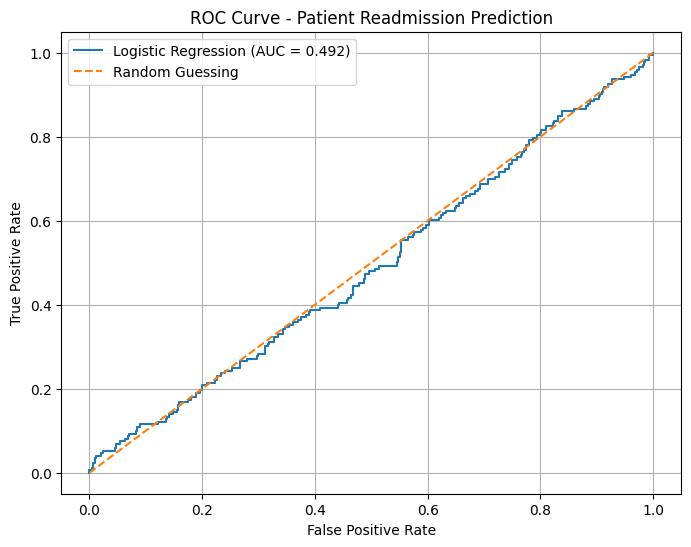

In [0]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr, tpr, thresholds_roc = roc_curve(y_test, test_probabilities)

# Calculate area under the curve
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Patient Readmission Prediction")

plt.legend()
plt.grid()
plt.show()

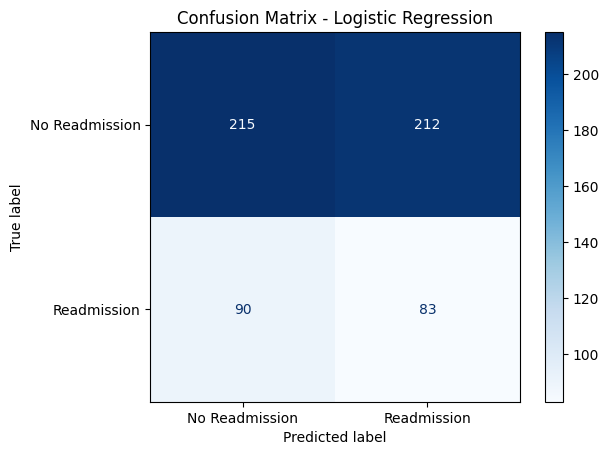

In [0]:
#Confusion Matrix Visualisation
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use threshold 0.50
final_predictions = (test_probabilities >= 0.50).astype(int)

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["No Readmission", "Readmission"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

Overfitting. Compare training and test performance for each model, and show a learning curve or validation
curve. Explain the strategies you used to limit overfitting: hold-out testing, cross-validation, regularisation, depth
and leaf limits, ensembles, feature reduction

The original Decision Tree and Random Forest memorised the training data very well but struggled to make reliable predictions on new patients. Tuning reduced this problem, but performance remained weak.

Logistic Regression has a smaller training/testing gap, but its overall predictive performance is also poor.

In [0]:
# Import required libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import pandas as pd

# Create a list of the five models
models = {
    "Logistic Regression": logistic_pipeline,

    "Decision Tree - Original": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree - Tuned": best_tree,

    "Random Forest - Original": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest - Tuned": best_rf
}

# Create an empty list to store results
results = []

# Train and evaluate each model
for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions on training data
    train_predictions = model.predict(X_train)
    train_probabilities = model.predict_proba(X_train)[:, 1]

    # Make predictions on test data
    test_predictions = model.predict(X_test_selected)
    test_probabilities_model = model.predict_proba(X_test_selected)[:, 1]

    # Calculate performance scores
    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_predictions),
        "Test Accuracy": accuracy_score(y_test, test_predictions),
        "Train ROC-AUC": roc_auc_score(y_train, train_probabilities),
        "Test ROC-AUC": roc_auc_score(y_test, test_probabilities_model)
    })

# Create and display the results table
overfitting_results = pd.DataFrame(results)

print(overfitting_results.round(4))

                      Model  Train Accuracy  ...  Train ROC-AUC  Test ROC-AUC
0       Logistic Regression          0.5117  ...         0.5340        0.4922
1  Decision Tree - Original          1.0000  ...         1.0000        0.5012
2     Decision Tree - Tuned          0.7733  ...         0.8589        0.5077
3  Random Forest - Original          1.0000  ...         1.0000        0.4839
4     Random Forest - Tuned          0.7133  ...         0.7798        0.4715

[5 rows x 5 columns]


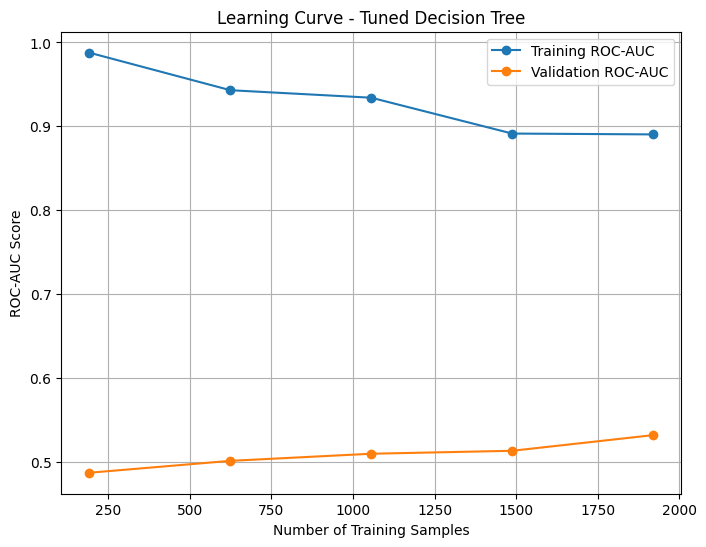

In [0]:
 # Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Calculate learning curve results
train_sizes, train_scores, validation_scores = learning_curve(
    best_tree,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

# Calculate average scores
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

# Plot the learning curve
plt.figure(figsize=(8, 6))

plt.plot(train_sizes, train_mean, marker="o", label="Training ROC-AUC")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation ROC-AUC")

plt.xlabel("Number of Training Samples")
plt.ylabel("ROC-AUC Score")
plt.title("Learning Curve - Tuned Decision Tree")

plt.legend()
plt.grid()
plt.show()

Limitations. Discuss what the model cannot tell the hospital, what data would improve it, and the ethical
considerations of acting on its predictions

5.1 Limitations of the model
Use the following points in your assignment:
1. Limited dataset: The dataset contains only 3,000 patient records and a limited number of clinical and demographic variables.
2. Weak predictive performance: The models achieved ROC-AUC scores close to 0.50, indicating that they struggle to distinguish between patients who will be readmitted and those who will not.
3. Missing clinical information: The dataset does not provide detailed diagnoses, medication history, discharge information, treatment plans or social circumstances that may influence readmission.
4. Generalisation: The models have only been evaluated using a training/test split and cross-validation on this dataset. They have not been validated on data from another hospital.
5. No causal explanation: The model identifies statistical patterns; it cannot establish why a patient is readmitted.
5.2 Ethical considerations
- Patient privacy: Patient information must be stored securely and accessed only by authorised people.
- Bias and fairness: The model should be checked to ensure that predictions do not unfairly disadvantage patients based on gender, age or other characteristics.
- Human oversight: Healthcare professionals must make the final decisions. The model should not replace clinical judgement.
- False negatives: A patient who is actually readmitted may be classified as low risk, potentially resulting in missed opportunities for additional care.
- False positives: A patient may be incorrectly classified as high risk, resulting in unnecessary follow-ups and additional healthcare costs.
5.3 Recommendations for improvement
The hospital should consider:
- Collecting more patient records from different hospitals.
- Including additional clinical information, such as diagnoses, medications and previous treatment history.
- Improving the quality and relevance of the available predictors.
- Testing the model on new and independent patient data.
- Monitoring model performance and fairness regularly.
Important finding: Based on the current results, none of the models is sufficiently reliable for actual hospital deployment. Further data collection, model development and external validation are required.